<p align="center">
  <img src="assets/hero_kavram.svg" width="100%" alt="Gün 56 — Hiyerarşik kümelemeye giriş: benzerden aileye">
</p>

<p align="center">
  <img src="https://img.shields.io/badge/G%C3%BCn-56-0E2A3B?style=for-the-badge" alt="Gün 56">
  <img src="https://img.shields.io/badge/Konu-Hiyerar%C5%9Fik_K%C3%BCmeleme_(Kavram)-34D399?style=for-the-badge" alt="Konu">
  <img src="https://img.shields.io/badge/Seviye-Ba%C5%9Flang%C4%B1%C3%A7-FBBF24?style=for-the-badge" alt="Seviye">
  <img src="https://img.shields.io/badge/Veri-167_%C3%BClke-38BDF8?style=for-the-badge" alt="Veri">
</p>

> *"Doğada her şey bir ağaca benzer: dallar dallara, aileler ailelere bağlanır."*
> Bugün bu ağacı **veriden** kendimiz çizeceğiz: 167 ülkenin **soy ağacını**.

<table><tr><td>

<img src="assets/etiket_hedef.svg" height="34" alt="Hedefler">

**Bu notebook'un sonunda şunları yapabiliyor olacaksınız:**

- 🌳 Hiyerarşik kümelemeyi **"aile ağacı"** benzetmesiyle, formüle boğulmadan anlatmak
- 📏 İki ülke arasındaki **benzerliği (mesafeyi)** hesaplamak ve bir **mesafe tablosu** okumak
- ✍️ 6 ülkeyle **elle birleştirme** yapıp `SciPy` ile birebir aynı sonucu almak
- ✂️ Bir **dendrogramı** okumak ve doğru yükseklikten **kesip** grupları seçmek
- 🔗 **Tek, tam, ortalama ve Ward** bağlantılarının farkını ve **zincirleme** tuzağını görmek
- ➗ **Ölçeklemenin** ağacı nasıl değiştirdiğini göstermek
- 🔢 Dendrogramdaki **büyük sıçramadan** küme sayısı önerisi çıkarmak
- 🪞 Ağacın gerçek mesafeleri ne kadar koruduğunu **kofenetik korelasyonla** ölçmek
- 🪓 **Bölerek** (yukarıdan aşağı) kümelemeyi, **DIANA** ile canlı izlemek
- ⚖️ Hiyerarşik kümeleme ile **K-Means** arasında bilinçli seçim yapmak, **yeni gelen ülkeyi** bir gruba atamak

</td></tr></table>

<p align="center">
  <img src="assets/yol_haritasi_kavram.svg" width="100%" alt="Kavram yol haritası: 13 durak">
</p>

### 🧭 Hızlı Erişim

| Durak | Bölüm | Ana soru |
|:-:|:--|:--|
| 🧰 1 | [Kurulum](#p1) | Hangi araçlarla çalışıyoruz? |
| 🌳 2 | [Aile ağacı fikri](#p2) | Hiyerarşi neden her yerde? Verimiz ne? |
| 📏 3 | [Benzerlik](#p3) | İki ülke ne kadar benziyor? |
| ✍️ 4 | [Elle birleştirme](#p4) | Ağaç adım adım nasıl kurulur? |
| 🎞️ 5 | [Canlı birleşme](#p5) | 20 ülke aileye nasıl dönüşür? |
| ✂️ 6 | [Dendrogramı kesmek](#p6) | Ağaçtan grup nasıl çıkar? |
| 🔗 7 | [Bağlantı yöntemleri](#p7) | İki AİLE arasındaki mesafe nasıl ölçülür? |
| ➗ 8 | [Ölçekleme](#p8) | Büyük sayılar neden ağacı bozar? |
| 🔢 9 | [Kaç küme?](#p9) | Ağacı nereden kesmeliyiz? |
| 🪞 10 | [Kofenetik ayna](#p10) | Ağaç gerçeği ne kadar iyi özetliyor? |
| 🪓 11 | [Bölerek: DIANA](#p11) | Yukarıdan aşağı da olur mu? |
| ⚖️ 12 | [Hiyerarşik mi, K-Means mi?](#p12) | Ne zaman hangisi? Yeni ülke nereye? |
| 🧠 13 | [Özet ve kaynakça](#p13) | Akılda ne kalmalı? |

<a id="p1"></a>

<p align="center">
  <img src="assets/kavram_01.svg" width="100%" alt="Bölüm 1: Kurulum">
</p>

Kütüphaneleri ve çizim yardımcılarını tek hücrede topluyoruz. Animasyonlar `outputs/figures` klasörüne **GIF** olarak kaydedilir ve notebook içinde oynatılır. Tüm rastgelelik `RANDOM_STATE = 42` ile sabitlenir. Veri okuma, Türkçe ülke adları ve elle yazılmış **DIANA** gibi yardımcılar `ulke_yardimci.py` dosyasındadır.

In [1]:
# ── Kütüphaneler ─────────────────────────────────────────────
import os, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, scipy
from IPython.display import Image, Markdown, display
from matplotlib.animation import FuncAnimation, PillowWriter
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet, set_link_color_palette
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.datasets import make_moons, make_blobs

from ulke_yardimci import (veri_oku, OZELLIKLER, BIRIM, LOG_SUTUNLARI, ISARETLI_LOG_SUTUNLARI,
                           isaretli_log, ticaret_kontrol, DIANA, AgacAtayici, dunya_haritasi)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ── Klasörler ────────────────────────────────────────────────
FIG = Path("outputs/figures"); REP = Path("outputs/reports")
FIG.mkdir(parents=True, exist_ok=True); REP.mkdir(parents=True, exist_ok=True)

# ── Renkler ve çizim stili ───────────────────────────────────
RENK = dict(altin="#F59E0B", mavi="#0EA5E9", pembe="#EC4899", yesil="#10B981", mor="#8B5CF6",
            turuncu="#F97316", cyan="#06B6D4", gri="#94A3B8", koyu="#0F172A")
KUME_RENK = [RENK[r] for r in ["yesil", "altin", "mavi", "pembe", "mor", "turuncu", "cyan"]] + ["#84CC16", "#E11D48", "#6366F1"]
set_link_color_palette(KUME_RENK[:7])                       # dendrogram dalları da aynı renkleri kullansın
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 13, "axes.spines.top": False, "axes.spines.right": False})

def kaydet(fig, ad):
    """Grafiği outputs/figures altına PNG olarak kaydeder."""
    fig.savefig(FIG / f"{ad}.png", dpi=130, bbox_inches="tight")

def rapor_kaydet(df, ad):
    """Tabloyu outputs/reports altına CSV olarak kaydeder (Excel'de Türkçe karakterler bozulmasın diye utf-8-sig)."""
    df.to_csv(REP / f"{ad}.csv", encoding="utf-8-sig")

def gif_yap(kare, n_kare, ad, boyut=(12, 5), fps=2, dpi=75):
    """kare(i, fig) fonksiyonunu her karede yeniden çizer, GIF olarak kaydeder ve notebook'ta oynatır."""
    fig = plt.figure(figsize=boyut)
    def ciz(i):
        fig.clf(); kare(i, fig); fig.tight_layout()
    FuncAnimation(fig, ciz, frames=n_kare).save(FIG / f"{ad}.gif", writer=PillowWriter(fps=fps), dpi=dpi)
    plt.close(fig)
    display(Image(filename=str(FIG / f"{ad}.gif")))

def on_isle(df):
    """Kavram notebook'unun basit ön işlemesi: çarpık sütunlara log, enflasyona işaretli log, sonra standartlaştırma.
    (Proje notebook'unda aynı adımlar eğitim/test ayrımına saygılı bir Pipeline içinde yapılır.)"""
    X = df[OZELLIKLER].astype(float).copy()
    X = X.fillna(X.median())                                  # eksik değer (ör. Myanmar'ın ticaret verisi) → medyan
    X[LOG_SUTUNLARI] = np.log1p(X[LOG_SUTUNLARI])
    X[ISARETLI_LOG_SUTUNLARI] = isaretli_log(X[ISARETLI_LOG_SUTUNLARI])
    return StandardScaler().fit_transform(X)

print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | scipy {scipy.__version__}")

pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | scipy 1.18.1


<a id="p2"></a>

<p align="center">
  <img src="assets/kavram_02.svg" width="100%" alt="Bölüm 2: Aile ağacı fikri">
</p>

### 🌳 2.1 · Hiyerarşi Her Yerde

Bir biyoloğun canlıları **tür → cins → aile → takım** diye sınıflaması, bilgisayarınızdaki **iç içe klasörler**, bir şirketin **organizasyon şeması**… Hepsi aynı fikre dayanır: **küçük grupları kademe kademe büyük gruplara bağlamak.**

<p align="center">
  <img src="assets/diyagram_aile_agaci.svg" width="100%" alt="Hiyerarşi her yerde">
</p>

**Hiyerarşik kümeleme** de tam olarak bunu yapar, ama **cevap anahtarı olmadan**: kimin kiminle aynı aileden olduğunu bize kimse söylemez; algoritma yalnızca **benzerliğe** bakarak ağacı kendisi kurar. Dün gördüğümüz K-Means bize **tek bir bölme** veriyordu ("3 grup"); hiyerarşik kümeleme ise **bütün bölmeleri birden** veren bir **ağaç** verir. Grup sayısını sonra, ağacı istediğimiz yükseklikten **keserek** seçeriz.

### ⬆️⬇️ 2.2 · Ağaç İki Yönden Kurulabilir

<p align="center">
  <img src="assets/diyagram_birlestir_bol.svg" width="100%" alt="Birleştirerek ve bölerek kümeleme">
</p>

- **Birleştirerek (agglomerative, aşağıdan yukarı):** Her ülke önce **kendi başına bir ailedir**. Her adımda **en benzer iki aile** birleşir. Sonunda herkes tek bir büyük ailede toplanır. *En yaygın yol budur; bu notebook'un büyük kısmı bunu anlatır.*
- **Bölerek (divisive, yukarıdan aşağı):** Herkes **tek bir ailede** başlar; her adımda en "uyumsuz" aile **ikiye bölünür**. (11. durakta **DIANA** ile canlı izleyeceğiz.)

### 🌍 2.3 · Bu Derste Kullanacağımız Veri: 167 Ülkenin Sağlık ve Ekonomi Karnesi

**Kaggle "Unsupervised Learning on Country Data"** verisi: 167 ülkenin **9 göstergesi**. Hikâyesi şöyle: bir uluslararası insani yardım kuruluşu, topladığı bağışı **en çok ihtiyacı olan** ülkelere yönlendirmek istiyor. Ama elinde "bu ülke yardıma muhtaç" diyen bir sütun **yok**. Yalnızca göstergeler var. Yardımcı dosyamız sütunlara Türkçe ad, ülkelere Türkçe isim ve kıta bilgisi ekler.

In [2]:
ulke = veri_oku()
print("Satır (ülke), sütun:", ulke.shape)
display(ulke[["Ülke", "Kıta"] + OZELLIKLER].head(6))

# Her göstergenin ne anlama geldiğini ve aralığını tek tabloda görelim
sozluk = pd.DataFrame({"Birim": pd.Series(BIRIM), "En düşük": ulke[OZELLIKLER].min(), "Medyan": ulke[OZELLIKLER].median(),
                       "En yüksek": ulke[OZELLIKLER].max()})
sozluk["En düşük ülke"] = [ulke.loc[ulke[s].idxmin(), "Ülke"] for s in OZELLIKLER]
sozluk["En yüksek ülke"] = [ulke.loc[ulke[s].idxmax(), "Ülke"] for s in OZELLIKLER]
display(sozluk.round(2))

Satır (ülke), sütun: (167, 13)


,Ülke,Kıta,Çocuk ölümü,İhracat,Sağlık harcaması,İthalat,Gelir,Enflasyon,Yaşam beklentisi,Doğurganlık,Kişi başı GSYH
0,Afganistan,Asya,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Arnavutluk,Avrupa,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Cezayir,Afrika,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,Afrika,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua ve Barbuda,Kuzey Amerika,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200
5,Arjantin,Güney Amerika,14.5,18.9,8.10,16.0,18700,20.90,75.8,2.37,10300


,Birim,En düşük,Medyan,En yüksek,En düşük ülke,En yüksek ülke
Çocuk ölümü,‰ (1000 doğumda),2.60,19.30,208.00,İzlanda,Haiti
İhracat,% GSYH,0.11,35.00,200.00,Myanmar,Singapur
Sağlık harcaması,% GSYH,1.81,6.32,17.90,Katar,ABD
İthalat,% GSYH,0.07,43.30,174.00,Myanmar,Singapur
Gelir,$ / kişi,609.00,9960.00,125000.00,Kongo Demokratik Cumhuriyeti,Katar
Enflasyon,%,-4.21,5.39,104.00,Seyşeller,Nijerya
Yaşam beklentisi,yıl,32.10,73.10,82.80,Haiti,Japonya
Doğurganlık,çocuk / kadın,1.15,2.41,7.49,Singapur,Nijer
Kişi başı GSYH,$ / kişi,231.00,4660.00,105000.00,Burundi,Lüksemburg


<table><tr><td>

<img src="assets/etiket_ipucu.svg" height="34" alt="İpucu">

**Etiket sütunu yok.** Tabloda "gelişmiş / gelişmekte / yardıma muhtaç" diye bir sütun göremezsiniz; hiyerarşik kümelemenin işi bu grupları **kendisi keşfetmek**. Ayrıca sütunların **birimleri çok farklı**: gelir 600 ile 125.000 dolar arasında, doğurganlık ise 1,2 ile 7,5 çocuk arasında. Bunun neden önemli olduğunu 8. durakta göreceğiz.

</td></tr></table>

### 🔍 2.4 · Bir Tuhaflık: Myanmar'ın Dış Ticareti

Tabloya dikkatli bakınca **Myanmar**'ın hem en düşük ihracat hem de en düşük ithalat değerine sahip olduğunu görüyoruz. Ne kadar düşük?

In [3]:
display(ulke.nsmallest(4, "İhracat")[["Ülke", "İhracat", "İthalat", "Kişi başı GSYH"]])
ulke = ticaret_kontrol(ulke)                                   # ihracat/ithalat < %1 GSYH → eksik (NaN) say
print("Eksik değer sayısı:", ulke[OZELLIKLER].isna().sum()[lambda s: s > 0].to_dict())

,Ülke,İhracat,İthalat,Kişi başı GSYH
107,Myanmar,0.109,0.0659,988
149,Doğu Timor,2.200,27.8000,3600
50,Eritre,4.790,23.3000,482
26,Burundi,8.920,39.2000,231


Eksik değer sayısı: {'İhracat': 1, 'İthalat': 1}


<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

Myanmar'ın ihracatı GSYH'nin **%0,11**'i, ithalatı **%0,07**'si görünüyor; listedeki bir sonraki ülkenin (Doğu Timor) ihracatı bile bunun **20 katı**. Dünyada dış ticareti ekonomisinin %1'inden küçük bir ülke yoktur; bu büyük olasılıkla bir **birim ya da veri giriş hatasıdır**. Bu tek hatalı sayı, logaritma alınınca Myanmar'ı dünyanın geri kalanından **kopuk tek kişilik bir aile** yapıyor (denedik!). Bu yüzden iki değeri **eksik** sayıp göstergenin **medyanıyla** dolduruyoruz. Proje notebook'unda bu kararı bir **karar defterine** yazıp sızıntısız biçimde uygulayacağız. Kümelemede **tek bir hatalı kayıt bütün ağacı bükebilir**: önce veriye bakın!

</td></tr></table>

### 👀 2.5 · Gözünüzle Kaç Aile Görüyorsunuz?

Önce yalnızca iki göstergeye bakalım: **kişi başı GSYH** ve **çocuk ölümü** (ikisi de çok çarpık olduğu için logaritmik eksende). Bazı ülkelerin adlarını da yazdık.

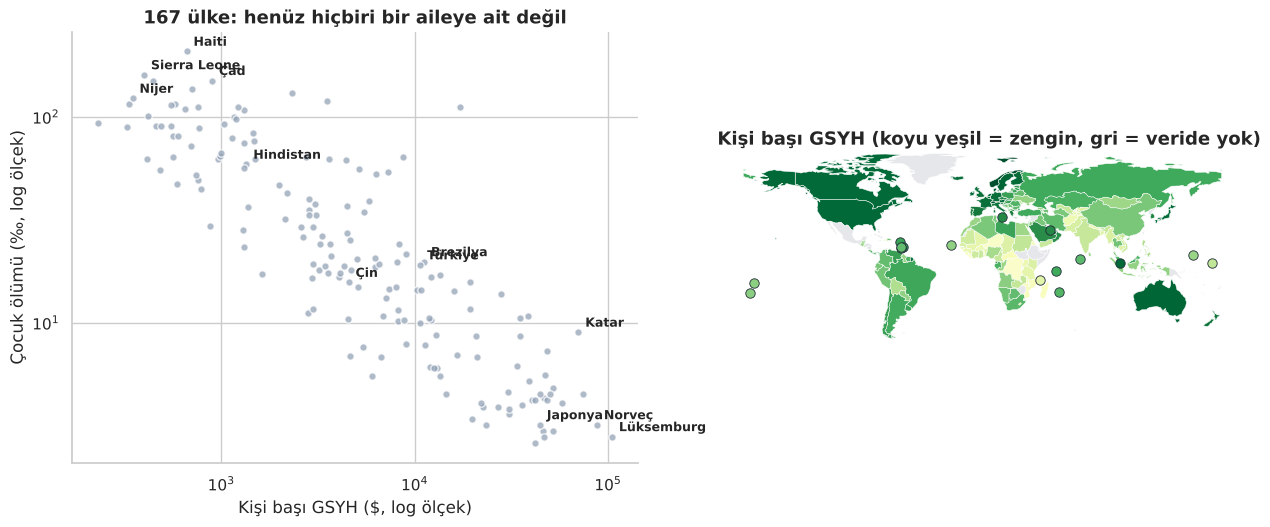

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1.15, 1]})
ax[0].scatter(ulke["Kişi başı GSYH"], ulke["Çocuk ölümü"], s=28, color=RENK["gri"], alpha=.75, edgecolor="white")
for ad in ["Türkiye", "Norveç", "Lüksemburg", "Katar", "Nijer", "Haiti", "Çad", "Hindistan", "Çin", "Brezilya", "Japonya", "Sierra Leone"]:
    r = ulke[ulke["Ülke"] == ad].iloc[0]
    ax[0].annotate(ad, (r["Kişi başı GSYH"], r["Çocuk ölümü"]), xytext=(5, 4), textcoords="offset points", fontsize=9, fontweight="bold")
ax[0].set(xscale="log", yscale="log", xlabel="Kişi başı GSYH ($, log ölçek)", ylabel="Çocuk ölümü (‰, log ölçek)",
          title="167 ülke: henüz hiçbiri bir aileye ait değil")

# Aynı ülkeleri dünya haritasında kişi başı GSYH ile boyayalım
renk_skala = plt.cm.YlGn((np.log(ulke["Kişi başı GSYH"]) - np.log(200)) / (np.log(110_000) - np.log(200)))
dunya_haritasi(ax[1], {u: c for u, c in zip(ulke["Ülke (EN)"], renk_skala)},
               baslik="Kişi başı GSYH (koyu yeşil = zengin, gri = veride yok)")
kaydet(fig, "kavram_01_ulkeler"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Sol grafikte bariz bir **eğim** var: kişi başı gelir arttıkça çocuk ölümü **hızla düşüyor**. Ama ülkeler ders kitabındaki gibi **birbirinden kopuk adalar** oluşturmuyor; daha çok **sürekli bir kuşak** üzerinde diziliyorlar. Yine de sol üstte (yoksul, çocuk ölümü yüksek) ve sağ altta (zengin, çocuk ölümü düşük) belirgin **yoğunluklar** göze çarpıyor. Hiyerarşik kümeleme bize "kaç aile var?" sorusunun **tek bir cevabını değil, her ölçekteki cevabını** verecek.

</td></tr></table>

<a id="p3"></a>

<p align="center">
  <img src="assets/kavram_03.svg" width="100%" alt="Bölüm 3: Benzerlik">
</p>

### 📏 3.1 · "Benzer" Ne Demek?

İki ülke, 9 göstergenin hepsinde birbirine yakınsa **benzerdir**. Bunu tek bir sayıya çevirmenin en yaygın yolu **Öklid mesafesidir** (kuş uçuşu uzaklık): göstergelerdeki farkların karelerini toplayıp karekökünü alırız. Her ülke çifti için bu sayıyı hesaplayınca bir **mesafe tablosu** (matrisi) elde ederiz.

<p align="center">
  <img src="assets/diyagram_mesafe.svg" width="100%" alt="Mesafe matrisi">
</p>

Altı ülkeyi seçip gerçek mesafe tablosunu hesaplayalım. Göstergeler önce aynı ölçeğe getirildi (log + standartlaştırma; nedeni 8. durakta).

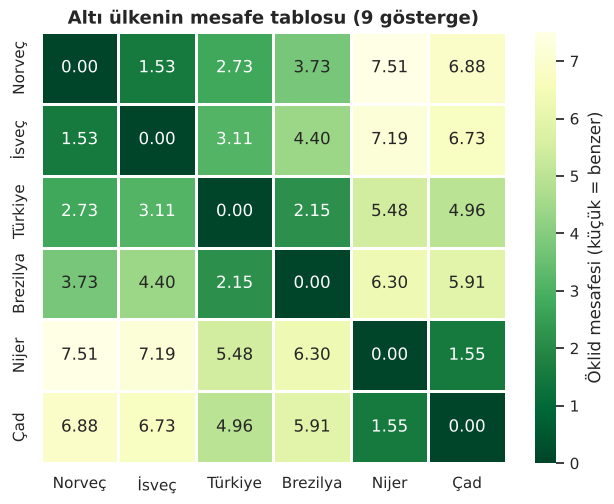

En benzer çift: Norveç – İsveç  (mesafe 1.53)
Toplam çift sayısı: 6 ülke → 15 | 167 ülke → 13.861


In [5]:
Z_tum = on_isle(ulke)                                         # 167 × 9: log + standart ölçek
alti = ["Norveç", "İsveç", "Türkiye", "Brezilya", "Nijer", "Çad"]
idx6 = [ulke.index[ulke["Ülke"] == a][0] for a in alti]
D6 = pd.DataFrame(squareform(pdist(Z_tum[idx6])), index=alti, columns=alti)   # pdist: tüm çiftlerin Öklid mesafesi

fig, ax = plt.subplots(figsize=(7.5, 5.6))
sns.heatmap(D6, annot=True, fmt=".2f", cmap="YlGn_r", cbar_kws={"label": "Öklid mesafesi (küçük = benzer)"}, ax=ax, linewidths=2)
ax.set_title("Altı ülkenin mesafe tablosu (9 gösterge)")
kaydet(fig, "kavram_02_mesafe_tablosu"); plt.show()
rapor_kaydet(D6.round(4), "kavram_mesafe_tablosu")

en_yakin = D6.where(np.triu(np.ones(D6.shape), 1).astype(bool)).stack().idxmin()
print(f"En benzer çift: {en_yakin[0]} – {en_yakin[1]}  (mesafe {D6.loc[en_yakin]:.2f})")
print(f"Toplam çift sayısı: 6 ülke → {6 * 5 // 2} | 167 ülke → {167 * 166 // 2:,}".replace(",", "."))

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Tablo **köşegeni sıfır** (her ülke kendine tıpatıp benzer) ve **simetrik** (Norveç'in İsveç'e uzaklığı = İsveç'in Norveç'e uzaklığı). Koyu kareler üç doğal çift gösteriyor: **İskandinav ikilisi**, **Türkiye–Brezilya** ve **Nijer–Çad**. Hiyerarşik kümelemenin ilk adımı tam olarak budur: tablodaki **en küçük sayıyı** bulup o iki ülkeyi birleştirmek.

</td></tr></table>

<a id="p4"></a>

<p align="center">
  <img src="assets/kavram_04.svg" width="100%" alt="Bölüm 4: Elle birleştirme">
</p>

### ✍️ 4.1 · 6 Ülke, Kalem Kâğıt

Algoritmanın sihir olmadığını görmek için aynı 6 ülkeyle ağacı **elle** kuralım. Kural çok basit:

1. Tablodaki **en küçük mesafeyi** bul → o iki aileyi **birleştir**.
2. Yeni ailenin diğerlerine uzaklığını hesapla. Burada en basit kuralı kullanıyoruz: **tek bağlantı**, yani "iki ailenin **en yakın** üyeleri arasındaki mesafe".
3. Tek aile kalana kadar tekrarla.

In [6]:
# Elle tek bağlantılı (single linkage) birleştirme
aileler = {i: [ad] for i, ad in enumerate(alti)}             # her ülke kendi başına bir aile
D = D6.to_numpy().copy()
adimlar = []
while len(aileler) > 1:
    anahtar = list(aileler)
    # Tüm aile çiftleri arasında en küçük "en yakın üye" mesafesini bul
    en_iyi = min(((a, b, min(D[alti.index(x), alti.index(y)] for x in aileler[a] for y in aileler[b]))
                  for i, a in enumerate(anahtar) for b in anahtar[i + 1:]), key=lambda t: t[2])
    a, b, h = en_iyi
    adimlar.append({"Adım": len(adimlar) + 1, "Birleşen aile 1": " + ".join(aileler[a]),
                    "Birleşen aile 2": " + ".join(aileler[b]), "Birleşme mesafesi": round(h, 4)})
    yeni = aileler.pop(a) + aileler.pop(b)
    aileler[len(alti) + len(adimlar)] = yeni                   # yeni aileye yeni bir numara ver
elle = pd.DataFrame(adimlar).set_index("Adım")
display(elle)

,Birleşen aile 1,Birleşen aile 2,Birleşme mesafesi
Adım,,,
1,Norveç,İsveç,1.5287
2,Nijer,Çad,1.5467
3,Türkiye,Brezilya,2.1502
4,Norveç + İsveç,Türkiye + Brezilya,2.7318
5,Nijer + Çad,Norveç + İsveç + Türkiye + Brezilya,4.9584


**Doğrulama:** Aynı altı ülkeyle `SciPy`'nin `linkage` fonksiyonunu (tek bağlantı) çalıştırıp birleşme mesafelerini karşılaştıralım; sonra ağacı (dendrogramı) çizelim.

Elle bulunan mesafeler : [1.5287, 1.5467, 2.1502, 2.7318, 4.9584]
SciPy mesafeleri       : [1.5287, 1.5467, 2.1502, 2.7318, 4.9584]
En büyük fark          : 4.875412570548576e-05


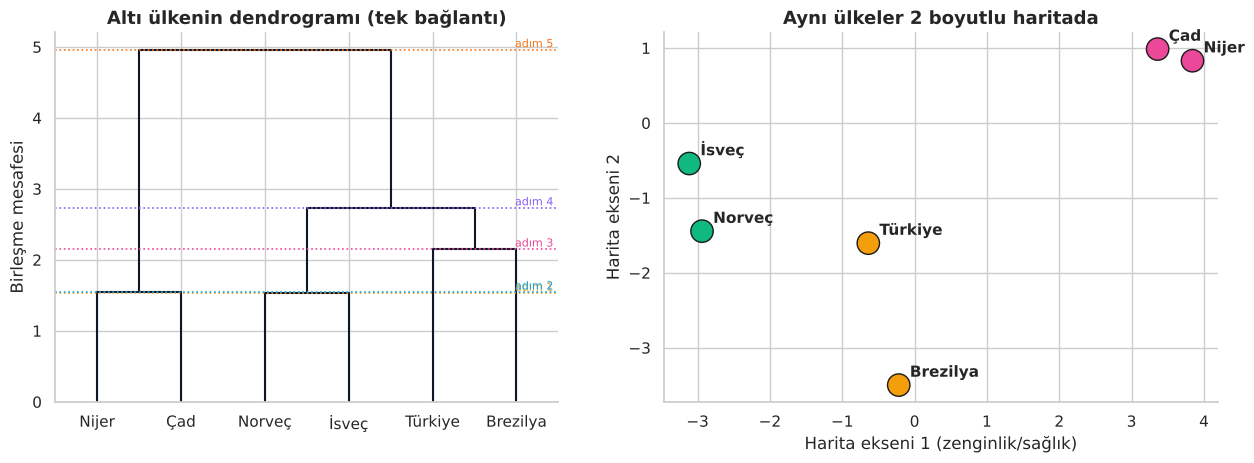

In [7]:
Z6 = linkage(Z_tum[idx6], method="single")                   # SciPy: her satır = bir birleşme (aile1, aile2, mesafe, boy)
print("Elle bulunan mesafeler :", elle["Birleşme mesafesi"].round(4).tolist())
print("SciPy mesafeleri       :", np.round(Z6[:, 2], 4).tolist())
print("En büyük fark          :", np.abs(np.sort(elle["Birleşme mesafesi"].to_numpy()) - np.sort(Z6[:, 2])).max())

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
dendrogram(Z6, labels=alti, ax=ax[0], color_threshold=0, above_threshold_color=RENK["koyu"], leaf_font_size=11)
ax[0].set(title="Altı ülkenin dendrogramı (tek bağlantı)", ylabel="Birleşme mesafesi")
for i, h in enumerate(Z6[:, 2], 1):
    ax[0].axhline(h, color=KUME_RENK[i], ls=":", lw=1.2); ax[0].text(ax[0].get_xlim()[1] * .99, h, f" adım {i}", va="bottom", ha="right", fontsize=8, color=KUME_RENK[i])
# Aynı ülkeler 2 boyutlu haritada (PCA, yalnızca görselleştirme için)
H6 = PCA(2, random_state=RANDOM_STATE).fit(Z_tum).transform(Z_tum[idx6])
ax[1].scatter(H6[:, 0], H6[:, 1], s=260, color=[KUME_RENK[j] for j in [0, 0, 1, 1, 3, 3]], edgecolor="k", zorder=3)
for (x, y), a in zip(H6, alti): ax[1].annotate(a, (x, y), xytext=(8, 6), textcoords="offset points", fontsize=11, fontweight="bold")
ax[1].set(title="Aynı ülkeler 2 boyutlu haritada", xlabel="Harita ekseni 1 (zenginlik/sağlık)", ylabel="Harita ekseni 2")
kaydet(fig, "kavram_03_elle_dendrogram"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Elle yaptığımız hesap ile `SciPy` **aynı birleşme mesafelerini** buldu. Hiyerarşik kümelemenin bütün "zekâsı" iki satırdır: **en benzer iki aileyi bul, birleştir; yeni ailenin uzaklıklarını güncelle.** Dendrogramdaki her **yatay çizgi** bir birleşmedir; çizginin **yüksekliği**, o iki aile birleşirken birbirinden **ne kadar farklı** olduğunu gösterir. İskandinav ikilisi en alttan (çok benzer), Avrupa ile Afrika aileleri en üstten (çok farklı) birleşiyor.

</td></tr></table>

<a id="p5"></a>

<p align="center">
  <img src="assets/kavram_05.svg" width="100%" alt="Bölüm 5: Canlı birleşme">
</p>

### 🎞️ 5.1 · 20 Ülke Adım Adım Aileleşiyor (Animasyon)

Şimdi farklı kıtalardan 20 ülke seçip birleşmeleri **canlı** izleyelim. Solda ülkeler 2 boyutlu haritada; aynı aileye giren ülkeler **aynı renge** boyanıyor ve bir çizgiyle bağlanıyor. Sağda ise **dendrogram dal dal büyüyor**. Bu kez bağlantı yöntemi **Ward** (birleşince aile içi dağınıklığı en az artıran ikiliyi seçer; 7. durakta ayrıntısı var).

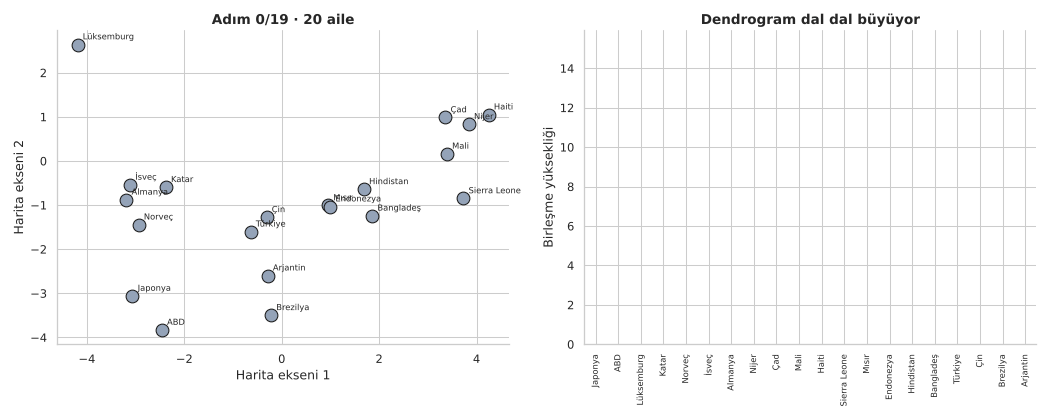

In [8]:
yirmi = ["Norveç", "İsveç", "Almanya", "Japonya", "ABD", "Katar", "Türkiye", "Brezilya", "Çin", "Arjantin",
         "Hindistan", "Mısır", "Endonezya", "Bangladeş", "Nijer", "Çad", "Mali", "Haiti", "Sierra Leone", "Lüksemburg"]
idx20 = [ulke.index[ulke["Ülke"] == a][0] for a in yirmi]
harita = PCA(2, random_state=RANDOM_STATE).fit(Z_tum)          # 9 boyutu 2 boyuta indiren "harita" (yalnızca çizim için)
H20, X20 = harita.transform(Z_tum[idx20]), Z_tum[idx20]
Z20 = linkage(X20, method="ward")                               # kümeleme 9 boyutta yapılır
d20 = dendrogram(Z20, labels=yirmi, no_plot=True)
n20 = len(yirmi)

# Her birleşmeden sonra hangi ülke hangi ailede? (adım t'de n20 - t aile vardır)
def aile_etiketi(t):
    return fcluster(Z20, n20 - t, criterion="maxclust") if t > 0 else np.arange(1, n20 + 1)

def kare(i, fig):
    t = min(i, n20 - 1)
    a1, a2 = fig.add_subplot(1, 2, 1), fig.add_subplot(1, 2, 2)
    et = aile_etiketi(t)
    boy = pd.Series(et).value_counts()
    sira = {k: j for j, k in enumerate(boy[boy > 1].index)}         # birden fazla üyesi olan ailelere renk ver
    for k in np.unique(et):
        m = et == k
        renk = KUME_RENK[sira[k] % len(KUME_RENK)] if k in sira else RENK["gri"]
        if m.sum() > 1:                                             # aile üyelerini merkeze bağla
            c = H20[m].mean(0)
            for p in H20[m]: a1.plot([p[0], c[0]], [p[1], c[1]], color=renk, lw=1.4, alpha=.6)
        a1.scatter(H20[m, 0], H20[m, 1], s=150, color=renk, edgecolor="k", zorder=3)
    for (x, y), a in zip(H20, yirmi): a1.annotate(a, (x, y), xytext=(5, 5), textcoords="offset points", fontsize=8)
    a1.set(title=f"Adım {t}/{n20 - 1} · {n20 - t} aile", xlabel="Harita ekseni 1", ylabel="Harita ekseni 2")
    # Sağ: dendrogramın bu adıma kadar olan dalları
    h_sinir = Z20[t - 1, 2] if t > 0 else -1
    for xs, ys in zip(d20["icoord"], d20["dcoord"]):
        if ys[1] <= h_sinir + 1e-9:
            a2.plot(xs, ys, color=RENK["mor"], lw=2)
    a2.set_xticks(np.arange(5, 10 * n20, 10)); a2.set_xticklabels(d20["ivl"], rotation=90, fontsize=8)
    a2.set(ylim=(0, Z20[:, 2].max() * 1.08), xlim=(0, 10 * n20), title="Dendrogram dal dal büyüyor", ylabel="Birleşme yüksekliği")
    if t > 0:
        a2.axhline(h_sinir, color=RENK["pembe"], ls="--", lw=1)

gif_yap(kare, n20 + 4, "kavram_02_canli_birlesme", boyut=(14, 5.6), fps=1.6)

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

İlk adımlar **çok kısa dallar**: birbirine çok benzeyen komşular (Norveç–İsveç, Nijer–Çad gibi) hemen birleşiyor. Sona doğru dallar **uzuyor**: artık birleşen aileler birbirinden **çok farklı**. Sondan bir önceki adımda orta gelirli ülkeler (Türkiye, Brezilya, Çin, Hindistan…) ile en yoksul beşli (Nijer, Çad, Mali, Haiti, Sierra Leone) birleşiyor; en son adımda da bu kalabalık aile, **yedi yüksek gelirli** ülkeyle (İskandinavya, Almanya, Japonya, ABD, Katar, Lüksemburg) buluşuyor. Bu son birleşme ağacın **en uzun dalı**. Ağacın bu "uzun dallarından" kesmek, en anlamlı ayrımları verir.

</td></tr></table>

<a id="p6"></a>

<p align="center">
  <img src="assets/kavram_06.svg" width="100%" alt="Bölüm 6: Dendrogramı kesmek">
</p>

### ✂️ 6.1 · Dendrogram Nasıl Okunur?

<p align="center">
  <img src="assets/diyagram_dendrogram_okuma.svg" width="100%" alt="Dendrogram okuma">
</p>

Ağacın sihri şu: **tek bir ağaç, bütün grup sayılarını birden içerir.** Ağacı yatay bir çizgiyle **keserseniz**, çizginin kestiği dikey dal sayısı kadar **aile** elde edersiniz. Çizgiyi yukarı kaydırın: az ama büyük aileler. Aşağı kaydırın: çok ama küçük aileler.

### 🎞️ 6.2 · Kesme Çizgisini Kaydıralım: 167 Ülke (Animasyon)

Solda 167 ülkenin tamamının Ward dendrogramı; pembe kesik çizgi yukarıdan aşağı kayıyor. Sağda aynı anda **dünya haritası**, o kesimin verdiği ailelerle boyanıyor.

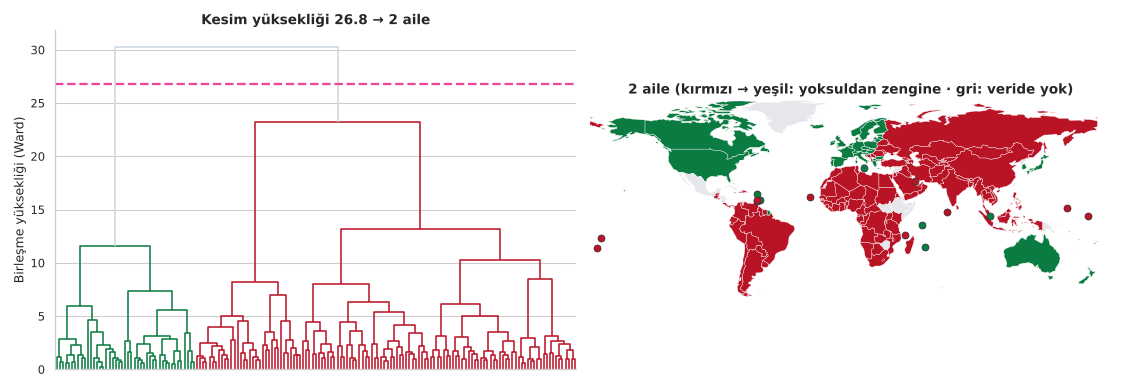

In [9]:
Z_ward = linkage(Z_tum, method="ward")                         # 167 ülkenin ağacı
yuk = Z_ward[:, 2]
kesimler = [(yuk[-k] + yuk[-k - 1]) / 2 for k in range(1, 8)]  # k = 2…8 aile veren kesim yükseklikleri
kesimler = kesimler + kesimler[::-1][1:-1]                      # aşağı in, sonra geri çık (döngü)

from matplotlib.colors import to_hex

def aile_renkleri(et):
    """Aileleri ortanca kişi başı GSYH'ye göre sırala; yoksuldan zengine kırmızı → sarı → yeşil renk ver."""
    sira = ulke.groupby(et)["Kişi başı GSYH"].median().sort_values().index
    palet = [to_hex(c) for c in plt.cm.RdYlGn(np.linspace(.04, .96, len(sira)))]
    return {aile: palet[j] for j, aile in enumerate(sira)}

def dal_renk_fonksiyonu(Zx, et, renk):
    """Dendrogramdaki her dalı, altındaki bütün ülkeler aynı ailedeyse o ailenin rengine boyar."""
    n = len(et); dugum = {i: et[i] for i in range(n)}
    for j, (a, b, *_) in enumerate(Zx):
        la, lb = dugum[int(a)], dugum[int(b)]
        dugum[n + j] = la if la == lb else None
    return lambda d: renk[dugum[d]] if dugum.get(d) is not None else "#CBD5E1"

def kare(i, fig):
    h = kesimler[i]
    a1 = fig.add_subplot(1, 2, 1); a2 = fig.add_subplot(1, 2, 2)
    et = fcluster(Z_ward, h, criterion="distance")
    renk = aile_renkleri(et); k = len(renk)
    dendrogram(Z_ward, ax=a1, no_labels=True, link_color_func=dal_renk_fonksiyonu(Z_ward, et, renk))
    a1.axhline(h, color=RENK["pembe"], ls="--", lw=2.2)
    a1.set(title=f"Kesim yüksekliği {h:.1f} → {k} aile", ylabel="Birleşme yüksekliği (Ward)")
    dunya_haritasi(a2, dict(zip(ulke["Ülke (EN)"], [renk[e] for e in et])), baslik=f"{k} aile (kırmızı → yeşil: yoksuldan zengine · gri: veride yok)")

gif_yap(kare, len(kesimler), "kavram_03_kesme_cizgisi", boyut=(15, 5.2), fps=1)

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**İki aileye** kestiğimizde dünya **45 yüksek gelirli ülke** (Kuzey Amerika, Batı ve Orta Avrupa, Japonya, Avustralya…) ile **geri kalan 122 ülke** diye ayrılıyor. **Üçe** inince bu kalabalık aile ikiye bölünüyor: ağırlıkla **Sahra Altı Afrika**'dan oluşan, kişi başı GSYH ortancası yalnızca **621 dolar** olan 34 ülke ve **orta gelirli** 88 ülke. Daha da inince orta gelirliler **alt-orta / üst-orta** diye, yüksek gelirliler **en zenginler / Orta-Doğu Avrupa ve Karayip adaları** diye ayrılıyor; altı ailede Arjantin, Brezilya, Çin, Körfez ülkeleri gibi **üst-orta gelirli** bir alt aile beliriyor. **Not:** Coğrafya modelde **hiç kullanılmadı**; harita yalnızca sonucu göstermek için. Kıtalar arası benzerlik, ülkelerin sağlık ve ekonomi göstergelerinin benzerliğinden **kendiliğinden** doğuyor.

</td></tr></table>

### 🏷️ 6.3 · Adlarıyla Okunabilir Bir Ağaç

167 yaprak okunamayacak kadar çok. 36 ülkelik rastgele bir örneklemle, **3 aileye** kesilmiş ve renklendirilmiş bir dendrogram çizelim.

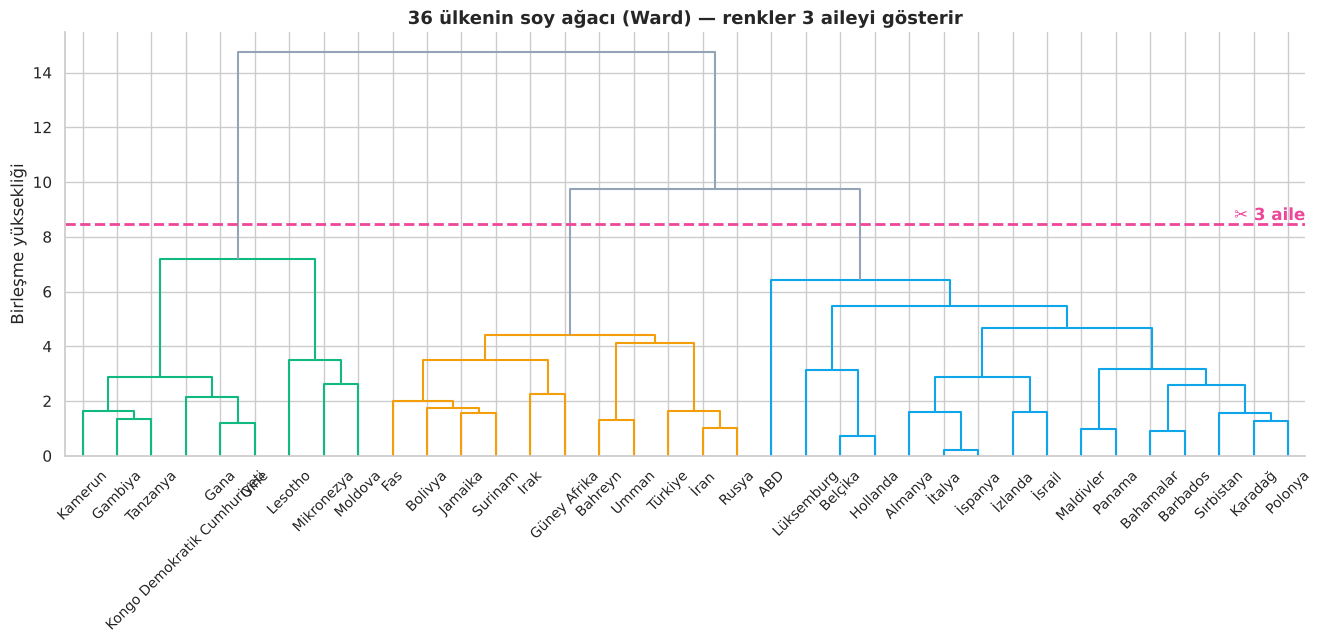

In [10]:
rng = np.random.default_rng(RANDOM_STATE)
ornek = np.sort(rng.choice(len(ulke), 36, replace=False))
Zo = linkage(Z_tum[ornek], method="ward")
esik = (Zo[-3, 2] + Zo[-2, 2]) / 2                               # tam 3 aile veren kesim
fig, ax = plt.subplots(figsize=(16, 5.5))
dendrogram(Zo, labels=ulke["Ülke"].to_numpy()[ornek], color_threshold=esik, above_threshold_color="#94A3B8", leaf_font_size=10, ax=ax)
ax.axhline(esik, color=RENK["pembe"], ls="--", lw=2); ax.text(ax.get_xlim()[1], esik, " ✂ 3 aile", color=RENK["pembe"], va="bottom", ha="right", fontweight="bold")
ax.set(title="36 ülkenin soy ağacı (Ward) — renkler 3 aileyi gösterir", ylabel="Birleşme yüksekliği")
kaydet(fig, "kavram_04_adli_dendrogram"); plt.show()

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

Dendrogramda ülkelerin **soldan sağa sırası** anlam taşımaz; bir dalı kendi ekseni etrafında döndürseniz ağaç **aynı ağaçtır**. Okurken yatay komşuluğa değil, **ilk hangi yükseklikte buluştuklarına** bakın: yan yana duran iki ülke, ağacın en tepesinde birleşiyor olabilir!

</td></tr></table>

<a id="p7"></a>

<p align="center">
  <img src="assets/kavram_07.svg" width="100%" alt="Bölüm 7: Bağlantı yöntemleri">
</p>

### 🔗 7.1 · İki AİLE Arasındaki Mesafe

İki **ülke** arasındaki mesafe kolaydı. Peki iki **aile** arasındaki mesafe? Bunun dört popüler cevabı var ve ağacın şeklini **tamamen** değiştirir:

<p align="center">
  <img src="assets/diyagram_baglantilar.svg" width="100%" alt="Bağlantı yöntemleri">
</p>

Aynı 20 ülkeyi dört yöntemle kümeleyip ağaçları yan yana koyalım:

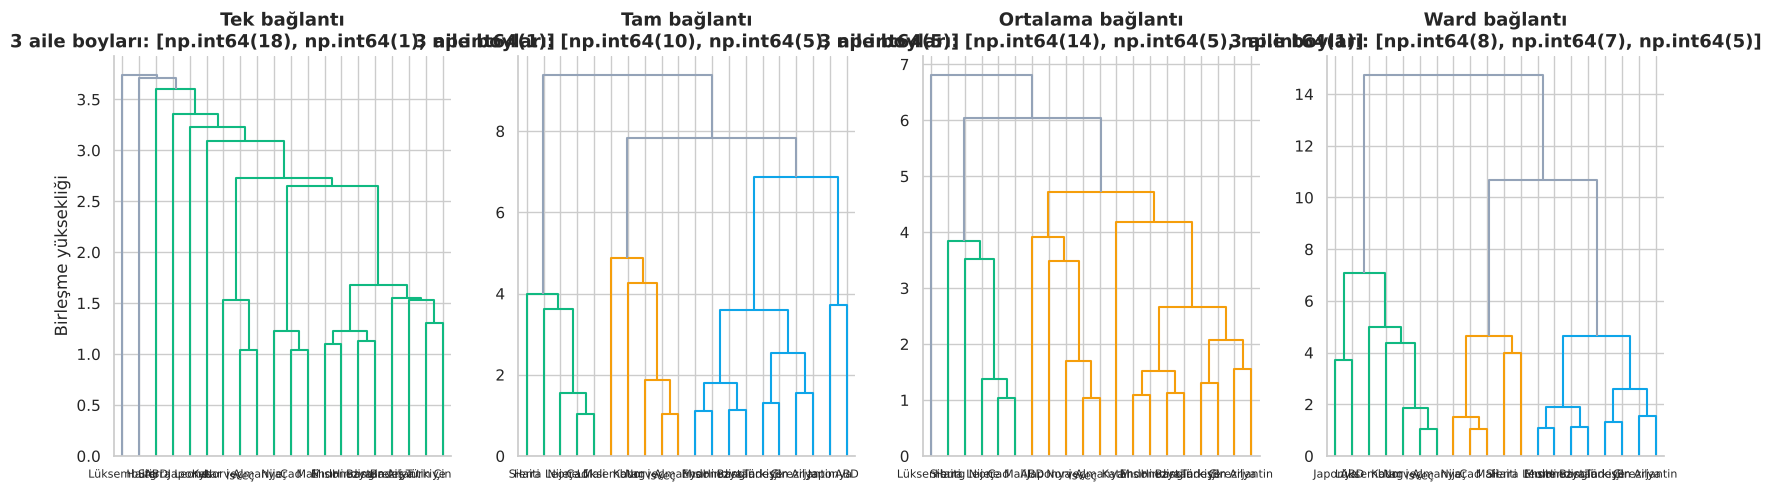

In [11]:
fig, ax = plt.subplots(1, 4, figsize=(20, 5.2))
baglanti_adi = {"single": "Tek", "complete": "Tam", "average": "Ortalama", "ward": "Ward"}
for a, (yontem, ad) in zip(ax, baglanti_adi.items()):
    Zb = linkage(X20, method=yontem)
    esik = (Zb[-3, 2] + Zb[-2, 2]) / 2
    dendrogram(Zb, labels=yirmi, ax=a, color_threshold=esik, above_threshold_color="#94A3B8", leaf_font_size=8)
    boylar = sorted(np.bincount(fcluster(Zb, 3, "maxclust"))[1:], reverse=True)
    a.set(title=f"{ad} bağlantı\n3 aile boyları: {boylar}", ylabel="Birleşme yüksekliği" if yontem == "single" else "")
kaydet(fig, "kavram_05_dort_baglanti"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**Tek bağlantıda** dallar kısa ve "basamaklı": ülkeler birer birer büyük aileye **eklemleniyor**; 3'e kestiğimizde **Haiti** ve **Lüksemburg** tek başına birer "aile" olurken kalan 18 ülke tek dev ailede toplanıyor (uç ülkeler ayrı düşüyor). **Ortalama bağlantı** da Lüksemburg'u yalnız bırakıyor. **Ward** ise en **dengeli** aileleri veriyor (7 zengin · 8 orta gelirli · 5 en yoksul) ve en üstteki dalları çok uzun: ayrım çok net. **Tam bağlantı** Ward'a yakın ama Japonya ve ABD'yi orta gelirlilerle birleştiriyor. Hangisinin "doğru" olduğunu veri ve amaç belirler.

</td></tr></table>

### ⛓️ 7.2 · Zincirleme Tuzağı ve Şekil Testi

<p align="center">
  <img src="assets/diyagram_zincirleme.svg" width="100%" alt="Zincirleme etkisi">
</p>

Farkı en net görmenin yolu, **şeklini bildiğimiz** verilerle denemek. Aşağıdaki üç veri **yapay (sentetik)** olarak üretildi *(gerçek değildir; yöntemlerin davranışını göstermek için)*: iç içe **hilaller**, boyları çok farklı **yuvarlak gruplar** ve **gürültülü** gruplar. Her yöntemin bulduğu aileyi gerçek grupla **ARI** ile karşılaştırıyoruz (1 = birebir aynı, 0 = rastgele).

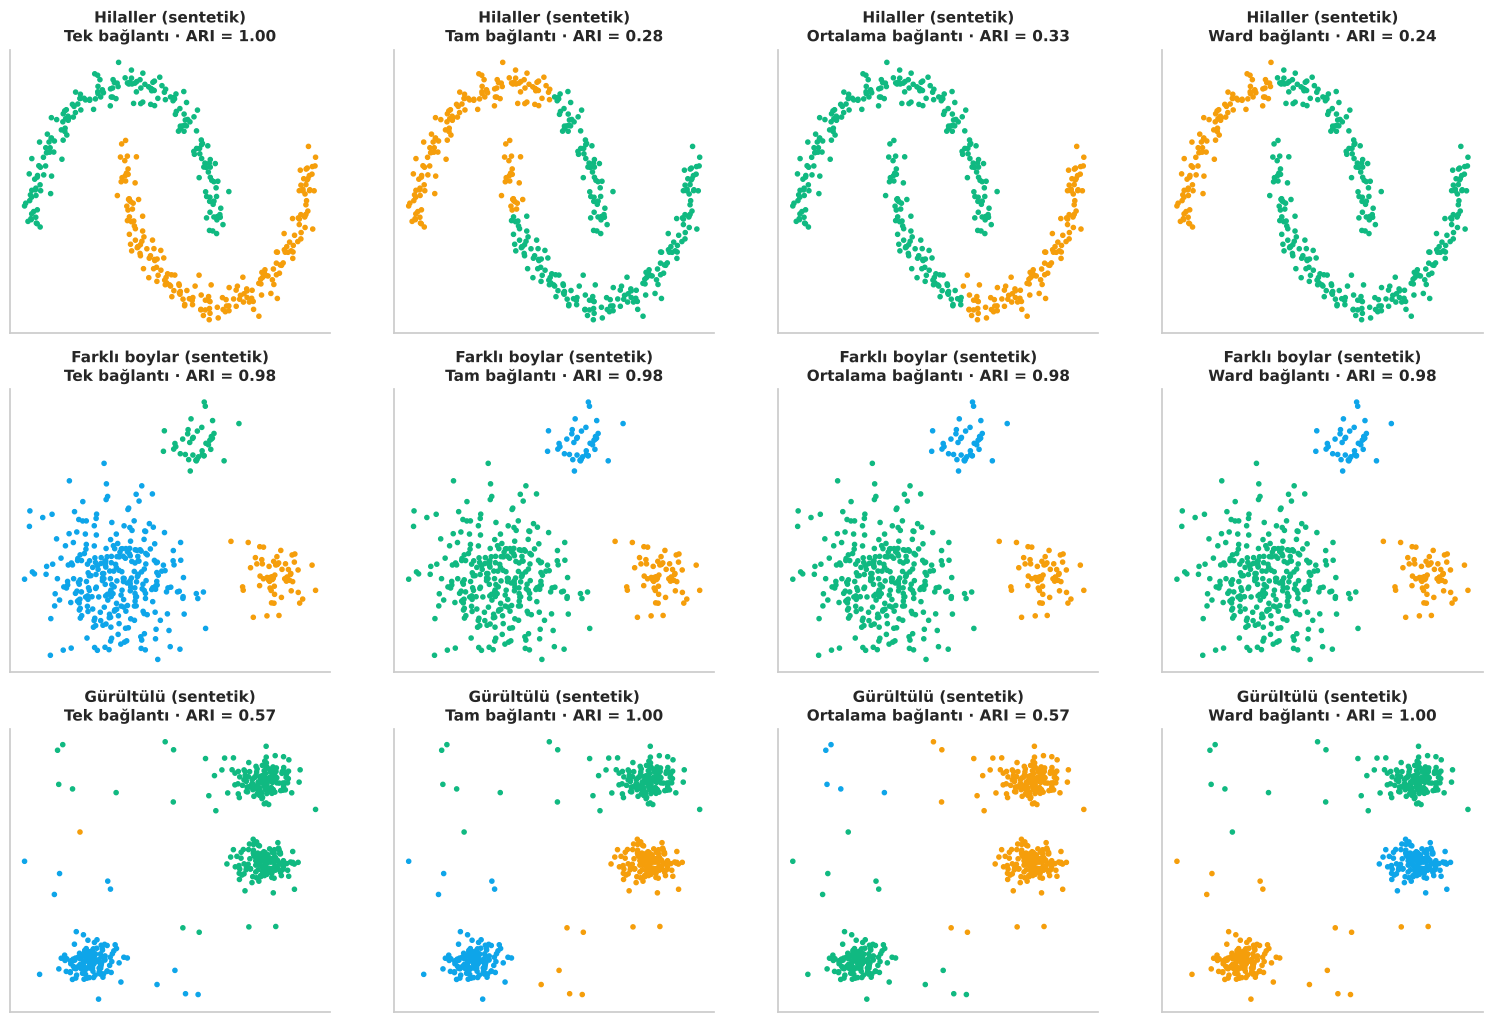

Bağlantı,Tek,Tam,Ortalama,Ward
Veri,,,,
Farklı boylar (sentetik),0.981,0.981,0.981,0.981
Gürültülü (sentetik),0.569,1.000,0.569,1.000
Hilaller (sentetik),1.000,0.285,0.329,0.239


In [12]:
Xh, yh = make_moons(400, noise=.06, random_state=0)
Xb, yb = make_blobs(n_samples=[300, 60, 40], centers=[[0, 0], [6, 0], [3, 5]], cluster_std=[1.3, .6, .6], random_state=2)
Xg, yg = make_blobs(400, centers=3, cluster_std=1.0, random_state=8)
Xg = np.vstack([Xg, np.random.default_rng(1).uniform(Xg.min(0) - 2, Xg.max(0) + 2, (40, 2))]); yg = np.r_[yg, -np.ones(40, int)]
setler = {"Hilaller (sentetik)": (Xh, yh, 2), "Farklı boylar (sentetik)": (Xb, yb, 3), "Gürültülü (sentetik)": (Xg, yg, 3)}

fig, ax = plt.subplots(3, 4, figsize=(19, 12.5)); sekil_ari = []
for r, (ad, (Xs, ys, k)) in enumerate(setler.items()):
    for c, (yontem, yad) in enumerate(baglanti_adi.items()):
        et = AgglomerativeClustering(k, linkage=yontem).fit_predict(Xs)
        ari = adjusted_rand_score(ys[ys >= 0], et[ys >= 0]); sekil_ari.append({"Veri": ad, "Bağlantı": yad, "ARI": ari})
        ax[r, c].scatter(Xs[:, 0], Xs[:, 1], s=9, c=[KUME_RENK[e] for e in et])
        ax[r, c].set_title(f"{ad}\n{yad} bağlantı · ARI = {ari:.2f}", fontsize=11); ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
kaydet(fig, "kavram_06_sekil_testi"); plt.show()
sekil_ari = pd.DataFrame(sekil_ari).pivot(index="Veri", columns="Bağlantı", values="ARI")[list(baglanti_adi.values())]
display(sekil_ari.round(3)); rapor_kaydet(sekil_ari.round(4), "kavram_sekil_ari")

### 🎞️ 7.3 · Tek Bağlantı ve Ward Yarışı: Hilaller (Animasyon)

Aynı hilal verisinde aile sayısı **40'tan 2'ye** inerken iki yöntemin birleşmelerini yan yana izleyelim. Tek bağlantı komşudan komşuya **zincir** kurar; Ward ise yuvarlak, dengeli aileler arar.

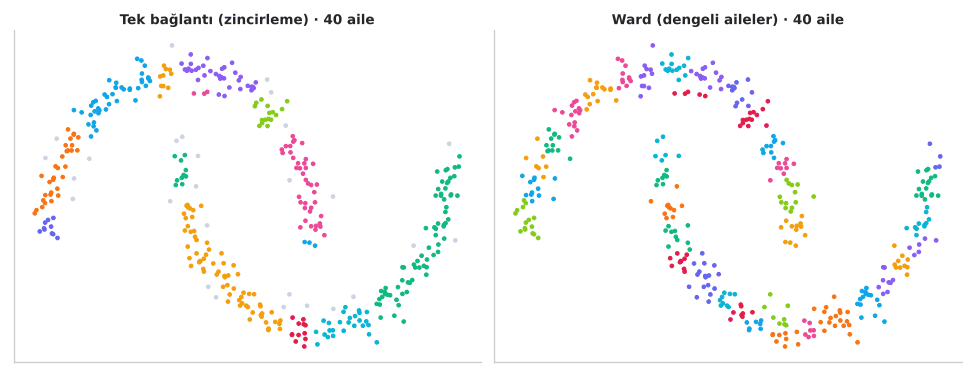

In [13]:
Zt, Zw = linkage(Xh, "single"), linkage(Xh, "ward")
k_dizi = [40, 30, 20, 14, 10, 8, 6, 5, 4, 3, 2, 2, 2]
def kare(i, fig):
    k = k_dizi[i]
    for j, (Zx, ad) in enumerate([(Zt, "Tek bağlantı (zincirleme)"), (Zw, "Ward (dengeli aileler)")]):
        a = fig.add_subplot(1, 2, j + 1)
        et = fcluster(Zx, k, "maxclust")
        boy = pd.Series(et).value_counts(); sira = {e: n for n, e in enumerate(boy.index)}
        a.scatter(Xh[:, 0], Xh[:, 1], s=12, c=[KUME_RENK[sira[e] % 10] if boy[e] > 2 else "#CBD5E1" for e in et])
        a.set(title=f"{ad} · {k} aile" + (f" · ARI {adjusted_rand_score(yh, et):.2f}" if k == 2 else ""), xticks=[], yticks=[])
gif_yap(kare, len(k_dizi), "kavram_04_zincirleme_yarisi", boyut=(13, 5), fps=1.4)

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**Hilallerde** kazanan **tek bağlantı** (ARI 1,00): komşudan komşuya zincir kurarak uzun, kıvrık şekli kusursuz takip ediyor; Ward, tam ve ortalama bağlantı ise hilalleri **düz bir çizgiyle** kesiyor (ARI ≤ 0,33). **Farklı boylarda** dört yöntem de başarılı (0,98). **Gürültülü** veride ise tablo tersine dönüyor: tek bağlantının zinciri gürültü noktaları üzerinden gruplar arasında **köprü** kuruyor (ARI 0,57; ortalama bağlantı da aynı), Ward ve tam bağlantı ise grupları kusursuz buluyor (1,00). Ülke verisi bir hilal değil; daha çok **gürültülü bulutlar**a benziyor. Bu yüzden projede Ward ve benzerleri öne çıkacak.

</td></tr></table>

<a id="p8"></a>

<p align="center">
  <img src="assets/kavram_08.svg" width="100%" alt="Bölüm 8: Ölçekleme">
</p>

### ➗ 8.1 · Büyük Sayılar Haksız Üstünlük Kurar

<p align="center">
  <img src="assets/diyagram_olcekleme.svg" width="100%" alt="Ölçeklemenin etkisi">
</p>

Deneyelim: 167 ülkeyi **ham** göstergelerle ve **ölçekli** göstergelerle Ward ağacına koyup 3'e kesiyoruz. Sonra her göstergenin aileleri ayırmadaki **söz hakkını** (η², eta-kare: o göstergedeki toplam farklılığın ne kadarı aileler arası farktan geliyor) ölçüyoruz.

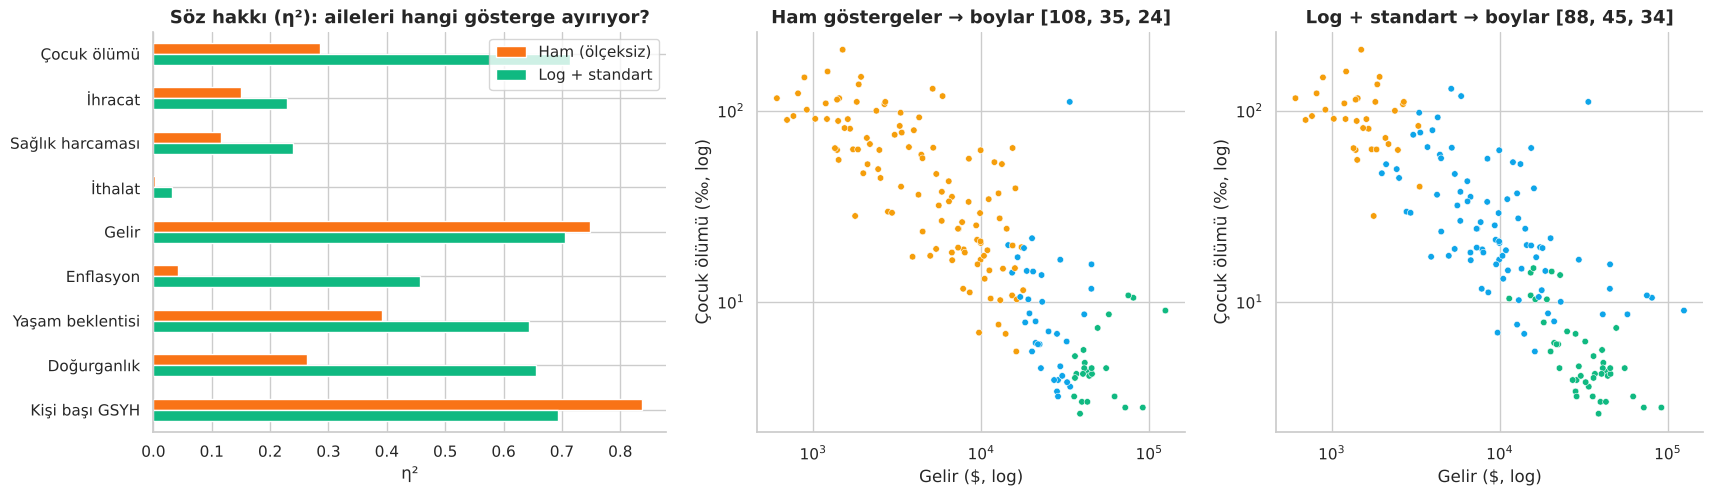

,Ham (ölçeksiz),Log + standart
Çocuk ölümü,0.285,0.713
İhracat,0.149,0.229
Sağlık harcaması,0.115,0.238
İthalat,0.003,0.031
Gelir,0.748,0.705
Enflasyon,0.041,0.456
Yaşam beklentisi,0.392,0.644
Doğurganlık,0.262,0.656
Kişi başı GSYH,0.837,0.693


In [14]:
def eta_kare(x, et):
    """Bir göstergenin toplam yayılımının, aileler arası farktan gelen payı (0 = hiç ayırmıyor, 1 = tamamen ayırıyor)."""
    x = np.asarray(x, float); genel = x.mean()
    ara = sum((et == j).sum() * (x[et == j].mean() - genel) ** 2 for j in np.unique(et))
    return ara / ((x - genel) ** 2).sum()

X_ham = ulke[OZELLIKLER].fillna(ulke[OZELLIKLER].median()).to_numpy(float)   # ham ama eksiksiz
et_ham = fcluster(linkage(X_ham, "ward"), 3, "maxclust")
et_olc = fcluster(Z_ward, 3, "maxclust")
soz = pd.DataFrame({"Ham (ölçeksiz)": [eta_kare(X_ham[:, j], et_ham) for j in range(9)],
                    "Log + standart": [eta_kare(Z_tum[:, j], et_olc) for j in range(9)]}, index=OZELLIKLER)

fig, ax = plt.subplots(1, 3, figsize=(20, 5.2), gridspec_kw={"width_ratios": [1.2, 1, 1]})
soz.plot.barh(ax=ax[0], color=[RENK["turuncu"], RENK["yesil"]]); ax[0].set(title="Söz hakkı (η²): aileleri hangi gösterge ayırıyor?", xlabel="η²"); ax[0].invert_yaxis()
for a, et, ad in [(ax[1], et_ham, "Ham göstergeler"), (ax[2], et_olc, "Log + standart")]:
    a.scatter(ulke["Gelir"], ulke["Çocuk ölümü"], s=22, c=[KUME_RENK[e - 1] for e in et], edgecolor="white", linewidth=.4)
    a.set(xscale="log", yscale="log", xlabel="Gelir ($, log)", ylabel="Çocuk ölümü (‰, log)", title=f"{ad} → boylar {sorted(np.bincount(et)[1:].tolist(), reverse=True)}")
kaydet(fig, "kavram_07_olcekleme"); plt.show()
display(soz.round(3)); rapor_kaydet(soz.round(4), "kavram_olcekleme")

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

Ham göstergelerle kurulan ağaçta aileleri büyük ölçüde **kişi başı GSYH** (η² 0,84) ve **gelir** (0,75) belirliyor; **çocuk ölümü** (0,29) ve **doğurganlık** (0,26) gibi hayati göstergelerin sesi kısık, çünkü onların sayıları küçük. Sonuç: en zengin 24 ülke bir aile, bir sonraki 35 ülke bir aile, dünyanın geri kalan **108 ülkesi** ise en yoksulu ile orta gelirlisi bir arada tek dev ailede. Log + standartlaştırma sonrası söz hakkı **göstergelere yayılıyor**: çocuk ölümü 0,71, gelir 0,71, kişi başı GSYH 0,69, doğurganlık 0,66, yaşam beklentisi 0,64. **Mesafeye dayanan her yöntemden önce** (hiyerarşik, K-Means, KNN, SVM…) göstergeleri aynı ölçeğe getirmek şarttır.

</td></tr></table>

<a id="p9"></a>

<p align="center">
  <img src="assets/kavram_09.svg" width="100%" alt="Bölüm 9: Kaç küme?">
</p>

### 🔢 9.1 · Dendrogramdaki Büyük Sıçrama

Ağacı nereden kesmeli? Sezgisel bir kural: **birleşme yüksekliklerinin aniden büyük sıçrama yaptığı** yerin hemen altından kes. Büyük sıçrama, "artık birbirine hiç benzemeyen aileleri zorla birleştiriyoruz" demektir. Bunu bir de **silüet** skoruyla (her ülke kendi ailesine, komşu aileden daha mı yakın?) kontrol edelim.

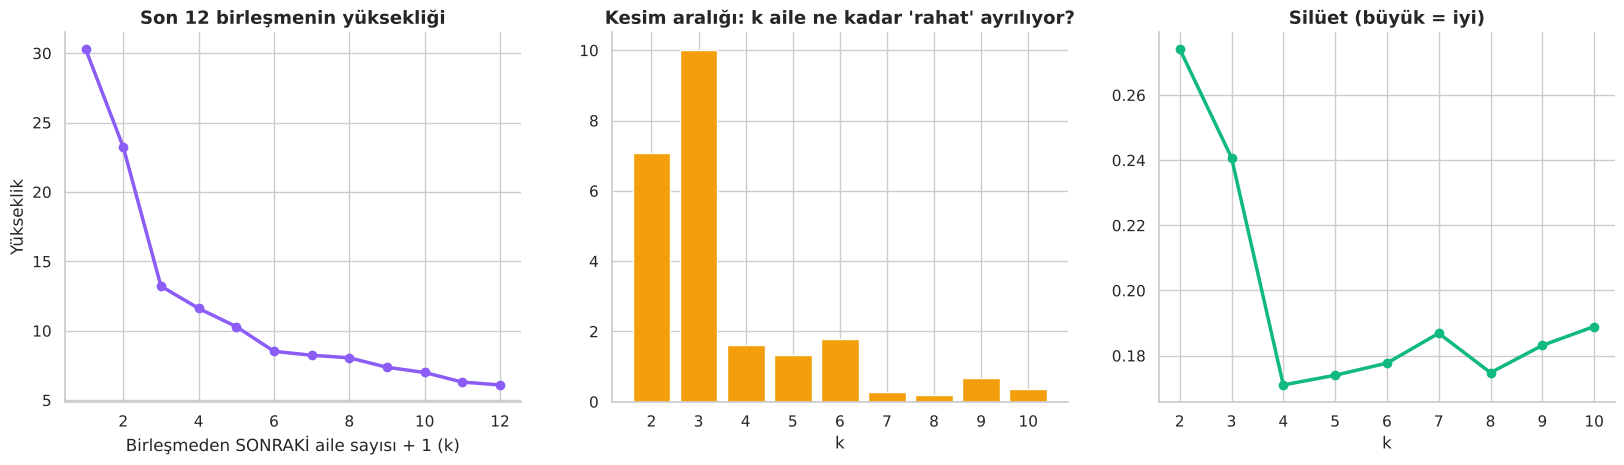

,Kesim aralığı (sıçrama),Silüet
k,,
2,7.076,0.274
3,10.015,0.241
4,1.603,0.171
5,1.317,0.174
6,1.777,0.178
7,0.284,0.187
8,0.184,0.175
9,0.684,0.183
10,0.375,0.189


In [15]:
son = Z_ward[-12:, 2][::-1]                                     # son 12 birleşmenin yüksekliği (büyükten küçüğe)
k_eks = np.arange(1, 13)
sicrama = -np.diff(son)                                          # k aile → k+1 aileye inerken yükseklik ne kadar düşüyor
sil = {k: silhouette_score(Z_tum, fcluster(Z_ward, k, "maxclust")) for k in range(2, 11)}
k_tab = pd.DataFrame({"Kesim aralığı (sıçrama)": pd.Series(sicrama[:10], index=range(2, 12)).reindex(range(2, 11)), "Silüet": pd.Series(sil)})
k_tab.index.name = "k"

fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
ax[0].plot(k_eks, son, "o-", color=RENK["mor"], lw=2.5); ax[0].set(title="Son 12 birleşmenin yüksekliği", xlabel="Birleşmeden SONRAKİ aile sayısı + 1 (k)", ylabel="Yükseklik")
ax[1].bar(k_tab.index, k_tab["Kesim aralığı (sıçrama)"], color=RENK["altin"]); ax[1].set(title="Kesim aralığı: k aile ne kadar 'rahat' ayrılıyor?", xlabel="k")
ax[2].plot(k_tab.index, k_tab["Silüet"], "o-", color=RENK["yesil"], lw=2.5); ax[2].set(title="Silüet (büyük = iyi)", xlabel="k")
for a in ax[1:]: a.set_xticks(range(2, 11))
kaydet(fig, "kavram_08_kac_kume"); plt.show()
display(k_tab.round(3)); rapor_kaydet(k_tab.round(4), "kavram_kac_kume")

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

En geniş kesim aralığı **k = 3**'te (≈ 10,0), ardından **k = 2** (≈ 7,1); k = 4'ten sonra aralıklar 2'nin altına iniyor: ağaç artık "ne kadar aşağıdan kesersen kes" benzer küçük bölünmeler veriyor. Silüet en yüksek değerini **k = 2**'de (0,27) veriyor, **k = 3** ikinci (0,24) ve sonra düşüyor. İki ölçüt de aynı şeyi söylüyor: ülke verisinde en güçlü ayrım **2–3 büyük aile** düzeyinde. Proje notebook'unda bu kararı **kararlılık** ve **iş kısıtıyla** birlikte, **önceden yazılmış bir kuralla** vereceğiz.

</td></tr></table>

<a id="p10"></a>

<p align="center">
  <img src="assets/kavram_10.svg" width="100%" alt="Bölüm 10: Kofenetik ayna">
</p>

### 🪞 10.1 · Ağaç Gerçek Mesafeleri Ne Kadar Koruyor?

Bir ağaç, ülkeler arasındaki 13.861 mesafeyi **tek bir hiyerarşiye** sıkıştırır; bu sıkıştırmada bilgi kaybolur. Ne kadar kaybolduğunu ölçmenin klasik yolu **kofenetik korelasyondur**:

<p align="center">
  <img src="assets/diyagram_kofenetik.svg" width="100%" alt="Kofenetik korelasyon">
</p>

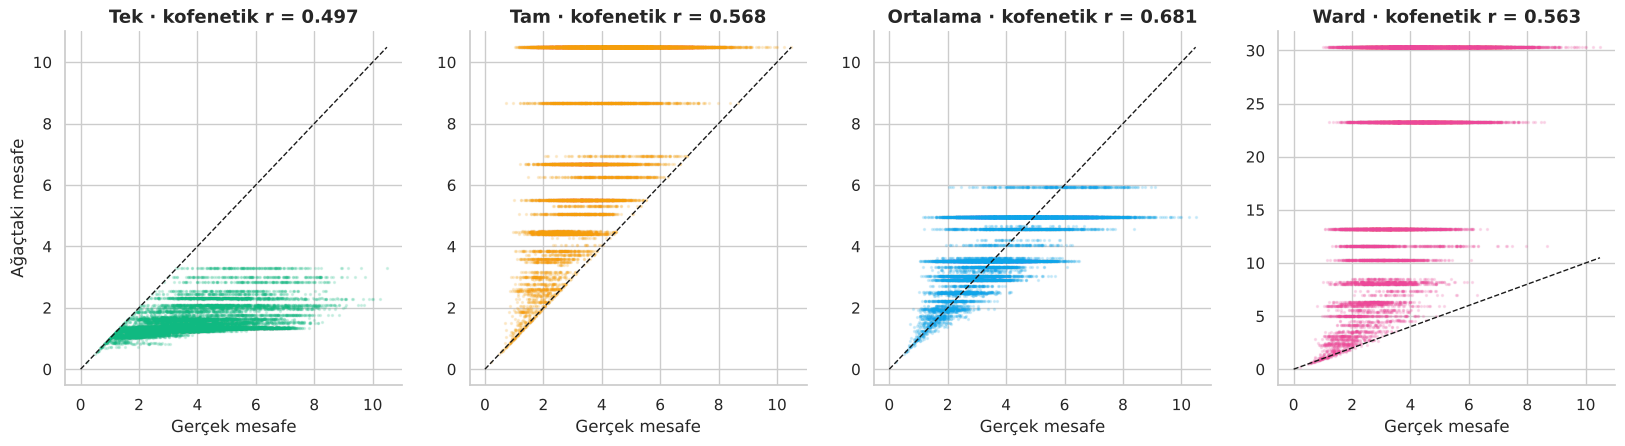

,Kofenetik korelasyon
Tek,0.497
Tam,0.568
Ortalama,0.681
Ward,0.563


In [16]:
gercek = pdist(Z_tum)
kof = {}
fig, ax = plt.subplots(1, 4, figsize=(20, 4.6))
for a, (yontem, ad) in zip(ax, baglanti_adi.items()):
    c, agac_mesafe = cophenet(linkage(Z_tum, yontem), gercek)   # c: kofenetik korelasyon
    kof[ad] = c
    a.scatter(gercek, agac_mesafe, s=2, alpha=.15, color=KUME_RENK[list(baglanti_adi).index(yontem)])
    a.plot([0, gercek.max()], [0, gercek.max()], "k--", lw=1)
    a.set(title=f"{ad} · kofenetik r = {c:.3f}", xlabel="Gerçek mesafe", ylabel="Ağaçtaki mesafe" if yontem == "single" else "")
kaydet(fig, "kavram_09_kofenetik"); plt.show()
kof = pd.Series(kof, name="Kofenetik korelasyon").round(3); display(kof.to_frame()); rapor_kaydet(kof.to_frame(), "kavram_kofenetik")

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

**Ortalama bağlantı** gerçek mesafeleri en iyi koruyan ağacı veriyor (r ≈ 0,68); tam bağlantı ve Ward ≈ 0,56–0,57, tek bağlantı ≈ 0,50. Ama dikkat: kofenetik korelasyon "ağaç mesafeleri **ne kadar doğru**" sorusunu cevaplar, "aileler **ne kadar kullanışlı**" sorusunu değil. Ward'ın ağacı mesafeleri biraz bozar ama **dengeli ve net ayrışan aileler** üretir. Ölçütleri **amaçla birlikte** okumak gerekir; proje notebook'unda kofenetik korelasyonu diğer ölçütlerin yanına koyacağız.

</td></tr></table>

<a id="p11"></a>

<p align="center">
  <img src="assets/kavram_11.svg" width="100%" alt="Bölüm 11: Bölerek: DIANA">
</p>

### 🪓 11.1 · Yukarıdan Aşağı: Tek Aileden Parçalara

**DIANA** (*DIvisive ANAlysis*), bölerek kümelemenin klasiğidir. Mantığı bir **ayrılık hikâyesi** gibidir:

1. Herkes **tek bir ailede** başlar. En "dağınık" aile (iki üyesi arasındaki en büyük mesafe = **çap**) seçilir.
2. Ailenin geri kalanına **ortalama en uzak** üye, aileden ayrılıp bir **kıymık grup** kurar.
3. Ailede kalanlardan, kıymık gruba **daha yakın** olanlar teker teker kıymığa geçer.
4. Kimse taraf değiştirmek istemeyince bölünme biter; istenen aile sayısına ulaşana kadar tekrarlanır.

Elle yazdığımız `DIANA` sınıfıyla 20 ülkeyi bölelim (Animasyon):

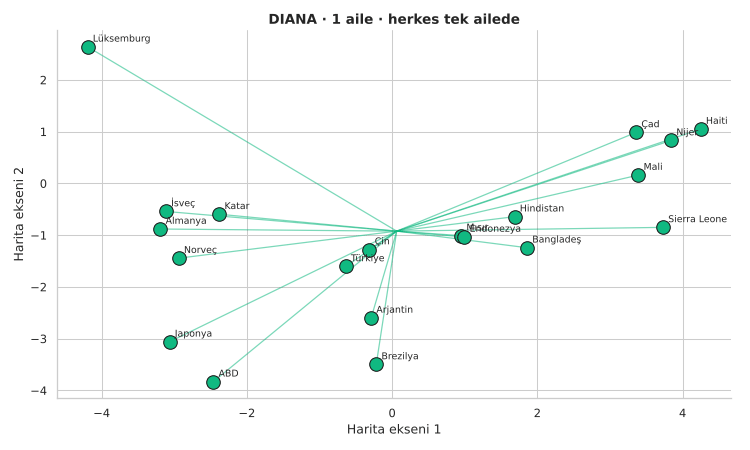

,DIANA ↔ Ward (ARI)
k,
2,0.133
3,0.435
4,0.505
5,0.524
6,0.411


— DIANA ilk bölünme —


,Kişi başı GSYH,Çocuk ölümü,Ülke sayısı
0,1185.0,64.0,70
1,12000.0,10.0,97


— Ward en üst dal —


,Kişi başı GSYH,Çocuk ölümü,Ülke sayısı
0,30700.0,4.0,45
1,2970.0,35.0,122


In [17]:
diana = DIANA(n_clusters=6).fit(X20)
def kare(i, fig):
    t = min(i, len(diana.adimlar_) - 1); et = diana.adimlar_[t]
    a = fig.add_subplot(1, 1, 1)
    for k in np.unique(et):
        m = et == k; c = H20[m].mean(0)
        for p in H20[m]: a.plot([p[0], c[0]], [p[1], c[1]], color=KUME_RENK[k], lw=1.2, alpha=.55)
        a.scatter(H20[m, 0], H20[m, 1], s=170, color=KUME_RENK[k], edgecolor="k", zorder=3)
    for (x, y), ad in zip(H20, yirmi): a.annotate(ad, (x, y), xytext=(5, 5), textcoords="offset points", fontsize=9)
    alt = f" · bölünen ailenin çapı {diana.bolmeler_[t - 1][1]:.2f}" if t > 0 else " · herkes tek ailede"
    a.set(title=f"DIANA · {t + 1} aile{alt}", xlabel="Harita ekseni 1", ylabel="Harita ekseni 2")
gif_yap(kare, len(diana.adimlar_) + 2, "kavram_05_diana_bolme", boyut=(10, 6), fps=0.8)

# 167 ülkede DIANA ile Ward ne kadar uyuşuyor?
uyum = pd.DataFrame([{"k": k, "DIANA ↔ Ward (ARI)": adjusted_rand_score(DIANA(k).fit_predict(Z_tum), fcluster(Z_ward, k, "maxclust"))} for k in range(2, 7)]).set_index("k")
display(uyum.round(3))

# İlk bölünmeleri yan yana: iki yöntem dünyayı ilk adımda nereden ikiye ayırıyor?
ilk = pd.DataFrame({"DIANA ilk bölünme": DIANA(2).fit_predict(Z_tum), "Ward en üst dal": fcluster(Z_ward, 2, "maxclust") - 1})
for s in ilk:
    g = ulke.groupby(ilk[s].to_numpy())[["Kişi başı GSYH", "Çocuk ölümü"]].median()
    g["Ülke sayısı"] = ilk[s].value_counts().sort_index().to_numpy()
    print(f"— {s} —"); display(g.round(0))

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Sürpriz: iki yön dünyayı **ilk adımda farklı yerden** ikiye ayırıyor. **Ward**'ın en üst dalı **45 yüksek gelirli** ülkeyi ayırırken, **DIANA** çizgiyi daha aşağıya, **düşük ve alt-orta gelirli 70 ülke** ile kalan 97 ülke arasına çekiyor; bu yüzden k = 2'de uyum (ARI) yalnızca ≈ 0,13. Aile sayısı 3–5'e çıkınca uyum ≈ 0,44–0,52'ye yükseliyor. Hangisi doğru? **İkisi de**: Ward "birleşince dağınıklığı en az artıran" aileleri, DIANA "en uyumsuz üyeleri koparan" bölünmeleri arar. Bu, hiyerarşik kümelemenin önemli bir dersidir: **ağacı kuran kural sonucu değiştirir**; tek bir ağaca körü körüne güvenmek yerine birkaç yöntemi karşılaştırmak gerekir (projede 27 algoritma yarışacak). Bedeli: DIANA her bölmede olası ayrılıkları tarttığı için büyük veride yavaştır.

</td></tr></table>

<a id="p12"></a>

<p align="center">
  <img src="assets/kavram_12.svg" width="100%" alt="Bölüm 12: Hiyerarşik mi, K-Means mi?">
</p>

### ⚖️ 12.1 · Ağacın Bedeli

<p align="center">
  <img src="assets/diyagram_hiz.svg" width="100%" alt="Bellek ve zaman">
</p>

Hiyerarşik kümeleme **tüm çiftlerin** mesafesine bakar; gözlem sayısı ikiye katlanınca iş yaklaşık **dört katına** çıkar. Bunu **yapay (sentetik)** verilerle ölçelim *(gerçek değildir; yalnızca süre ölçümü için)*:

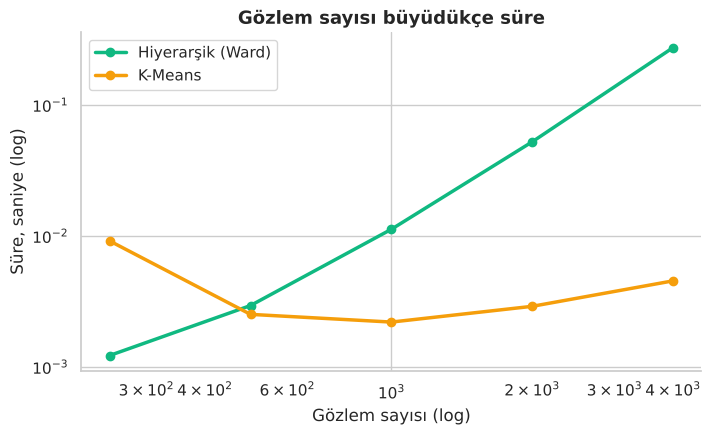

Yöntem,Hiyerarşik (Ward),K-Means,Mesafe matrisi (MB)
n,,,
250,0.0012,0.0092,0.249
500,0.0029,0.0025,0.998
1000,0.0113,0.0022,3.996
2000,0.0525,0.0029,15.992
4000,0.2752,0.0045,63.984


In [18]:
sure = []
for n in [250, 500, 1000, 2000, 4000]:
    Xs, _ = make_blobs(n, centers=4, n_features=9, random_state=0)
    for ad, model in [("Hiyerarşik (Ward)", AgglomerativeClustering(4)), ("K-Means", KMeans(4, n_init=3, random_state=RANDOM_STATE))]:
        t0 = time.perf_counter(); model.fit(Xs); sure.append({"n": n, "Yöntem": ad, "Süre (sn)": time.perf_counter() - t0})
sure = pd.DataFrame(sure).pivot(index="n", columns="Yöntem", values="Süre (sn)")
sure["Mesafe matrisi (MB)"] = [n * (n - 1) / 2 * 8 / 1e6 for n in sure.index]
fig, ax = plt.subplots(figsize=(8, 4.4))
for s, r in [("Hiyerarşik (Ward)", RENK["yesil"]), ("K-Means", RENK["altin"])]:
    ax.plot(sure.index, sure[s], "o-", color=r, lw=2.5, label=s)
ax.set(xscale="log", yscale="log", xlabel="Gözlem sayısı (log)", ylabel="Süre, saniye (log)", title="Gözlem sayısı büyüdükçe süre"); ax.legend()
kaydet(fig, "kavram_10_sure"); plt.show()
display(sure.round(4)); rapor_kaydet(sure.round(5), "kavram_sure")

### 🆕 12.2 · Yeni Gelen Ülke Hangi Aileye?

K-Means'in `predict()` yöntemi vardı: yeni gelen, **en yakın yıldıza** gider. Hiyerarşik kümelemenin böyle bir yöntemi **yoktur**: ağaç, kurulduğu ülkelerle **sabittir**; yeni bir yaprak eklemek için ağacı baştan kurmak gerekir. Pratik çözüm: ağacı kurduktan sonra her ailenin **merkezini** (ortalamasını) hesaplayıp yeni geleni **en yakın merkeze** atamak. Yardımcı dosyamızdaki `AgacAtayici` tam olarak bunu yapar.

Deneyelim: **Türkiye'yi ve 9 ülkeyi** veriden çıkarıp ağacı kalan 157 ülkeyle kuralım, sonra bu 10 ülkeyi "yeni gelen" gibi atayalım.

In [19]:
yeni_adlar = ["Türkiye", "Vietnam", "Kenya", "Polonya", "Peru", "Pakistan", "Kanada", "Ruanda", "Fas", "Güney Kore"]
yeni_mask = ulke["Ülke"].isin(yeni_adlar).to_numpy()
atayici = AgacAtayici(AgglomerativeClustering(3, linkage="ward")).fit(Z_tum[~yeni_mask])   # NOT: kavram için basit; projede ölçekleme de yalnızca eğitimden öğrenilir

# Aileleri ortanca kişi başı GSYH'ye göre adlandır (yoksuldan zengine)
egitim = ulke[~yeni_mask].assign(Aile=atayici.labels_)
sira = egitim.groupby("Aile")["Kişi başı GSYH"].median().sort_values().index
ad = dict(zip(sira, ["🆘 Düşük gelir, yüksek çocuk ölümü", "🌱 Orta gelir", "🏙️ Yüksek gelir"]))
tahmin = atayici.predict(Z_tum[yeni_mask])
uzak = atayici.transform(Z_tum[yeni_mask])
sonuc = ulke.loc[yeni_mask, ["Ülke", "Kişi başı GSYH", "Çocuk ölümü", "Yaşam beklentisi"]].assign(
    **{"Atanan aile": [ad[t] for t in tahmin], "En yakın merkeze uzaklık": uzak.min(1).round(2),
       "İkinci en yakına uzaklık": np.sort(uzak, 1)[:, 1].round(2)})
display(sonuc.set_index("Ülke"))

,Kişi başı GSYH,Çocuk ölümü,Yaşam beklentisi,Atanan aile,En yakın merkeze uzaklık,İkinci en yakına uzaklık
Ülke,,,,,,
Kanada,47400,5.6,81.3,🏙️ Yüksek gelir,1.82,3.60
Kenya,967,62.2,62.8,"🆘 Düşük gelir, yüksek çocuk ölümü",1.59,2.72
Fas,2830,33.5,73.5,🌱 Orta gelir,1.65,3.10
Pakistan,1040,92.1,65.3,"🆘 Düşük gelir, yüksek çocuk ölümü",2.95,3.26
Peru,5020,20.3,77.9,🌱 Orta gelir,1.52,3.28
Polonya,12600,6.0,76.3,🏙️ Yüksek gelir,1.06,2.44
Ruanda,563,63.6,64.6,"🆘 Düşük gelir, yüksek çocuk ölümü",2.00,3.83
Güney Kore,22100,4.1,80.1,🏙️ Yüksek gelir,1.26,2.88
Türkiye,10700,19.1,78.2,🌱 Orta gelir,1.88,2.93


<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Yeni gelen ülkeler beklediğimiz ailelere düştü: Kanada ve Güney Kore **yüksek gelirli** aileye, Pakistan, Kenya ve Ruanda **düşük gelirli, çocuk ölümü yüksek** aileye, Türkiye, Vietnam ve Fas **orta gelirli** aileye. Son iki sütuna bakın: en yakın ile ikinci en yakın merkeze uzaklıklar **birbirine yakınsa**, ülke iki aile arasında bir **sınır ülkesidir**; böyle ülkeler için karar verirken daha dikkatli olmak gerekir.

</td></tr></table>

### 🧭 12.3 · Hangisini Ne Zaman Seçmeli?

| Durum | Hiyerarşik kümeleme | K-Means |
|:--|:--|:--|
| Grup sayısını **önceden bilmiyorum** | ✅ Ağacı kur, sonra kes; tüm seçenekler önünde | ⚠️ k'yı vermek zorundasın |
| **Ağaç / soy ilişkisi** anlam taşıyor (ülkeler, türler, belgeler) | ✅ Dendrogram tek başına bir içgörüdür | ❌ Yalnızca düz bölme |
| Veri **küçük-orta** (birkaç bin) | ✅ Rahat | ✅ Rahat |
| Veri **çok büyük** (yüz binler) | ❌ n² bellek ve zaman | ✅ Hızlı |
| **Yeni gözlemi** atamak | ⚠️ Ek bir atayıcı gerekir | ✅ `predict()` hazır |
| **Sonuç tekrarlanabilirliği** | ✅ Deterministik (rastgelelik yok) | ⚠️ Başlangıca bağlı (`n_init`) |
| **Uzun, kıvrık** şekiller | ✅ Tek bağlantıyla mümkün | ❌ Yuvarlak gruplar varsayar |

<a id="p13"></a>

<p align="center">
  <img src="assets/kavram_13.svg" width="100%" alt="Bölüm 13: Özet">
</p>

### 🧠 Akılda Kalacaklar

<table>
<tr><td width="33%" valign="top" align="center"><h3>🌳</h3><b>Bir ağaç, bütün cevaplar</b><br><sub><i>dendrogram</i></sub><br><br>Hiyerarşik kümeleme tek bir bölme değil, <b>her ölçekteki</b> bölmeyi birden verir<br><br></td><td width="33%" valign="top" align="center"><h3>🤝</h3><b>İki satırlık algoritma</b><br><sub><i>bul · birleştir · güncelle</i></sub><br><br>En benzer iki aileyi birleştir; elle de, SciPy ile de <b>aynı ağaç</b><br><br></td><td width="33%" valign="top" align="center"><h3>✂️</h3><b>Yükseklik = farklılık</b><br><sub><i>kesim çizgisi</i></sub><br><br>Uzun dallar net ayrımlardır; <b>büyük sıçramanın altından</b> kes<br><br></td></tr>
<tr><td valign="top" align="center"><h3>🔗</h3><b>Bağlantı ağacı biçimler</b><br><sub><i>tek · tam · ortalama · Ward</i></sub><br><br>Tek bağlantı <b>zincir</b> kurar; Ward <b>dengeli</b> aileler arar<br><br></td><td valign="top" align="center"><h3>➗</h3><b>Önce ölçekle</b><br><sub><i>log + standart</i></sub><br><br>Yoksa büyük sayılı gösterge (gelir) <b>tek başına</b> karar verir<br><br></td><td valign="top" align="center"><h3>🪞</h3><b>Ağacın aynası</b><br><sub><i>kofenetik korelasyon</i></sub><br><br>Ağaç gerçek mesafeleri ne kadar koruyor? <b>Amaçla birlikte</b> oku<br><br></td></tr>
<tr><td valign="top" align="center"><h3>🪓</h3><b>İki yön</b><br><sub><i>AGNES ↑ · DIANA ↓</i></sub><br><br>Yukarıdan aşağı "en büyük ayrım", aşağıdan yukarı "en yakın komşu"<br><br></td><td valign="top" align="center"><h3>⏱️</h3><b>Ağacın bedeli</b><br><sub><i>n² bellek</i></sub><br><br>Küçük-orta veride ideal; çok büyük veride K-Means veya BIRCH<br><br></td><td valign="top" align="center"><h3>🆕</h3><b>Yeni gelen ülke</b><br><sub><i>en yakın merkez</i></sub><br><br>Ağaçta <code>predict()</code> yok; aile merkezleriyle <b>atayıcı</b> kurulur<br><br></td></tr>
</table>

<p align="center">
  <img src="assets/kapanis_kavram.svg" width="100%" alt="Kapanış">
</p>

### 🔜 Sırada Ne Var?

**`day56_hiyerarsik_ulke_projesi.ipynb`**: aynı 167 ülkeyle uçtan uca bir proje. Kilitli test seti, sızıntısız boru hattı, **önceden yazılmış kurallar**, **27 algoritmanın** yarışı, kararlılık, ayar, **BM En Az Gelişmiş Ülkeler** listesiyle bağımsız doğrulama, yardım önceliği ve adalet denetimi.

### 📚 KAYNAKÇA

Metin içi atıflar APA 7 biçimindedir. **Dolaylı atıf**, kaynağa ikinci elden ulaşıldığında "(B, A'dan aktarma)" kalıbıyla gösterilir. Bu notebook'taki örnekler:

- Tek bağlantılı kümeleme fikri sayısal taksonomideki erken çalışmalara dayanır (Sneath, 1957; Murtagh ve Contreras, 2012'den aktarma). Tek bağlantının en küçük kapsayan ağaçla (minimum spanning tree) eşdeğerliği Gower ve Ross (1969) tarafından gösterilmiştir.
- Ward bağlantısı, birleşmede **grup içi kareler toplamındaki artışı** en küçük yapan ölçüte dayanır (Ward, 1963; Murtagh ve Legendre, 2014'ten aktarma).
- Ortalama bağlantı (UPGMA) Sokal ve Michener'in (1958) çalışmasına dayanır (Sokal ve Michener, 1958; Murtagh ve Contreras, 2012'den aktarma); tüm bu bağlantıların tek bir güncelleme formülüyle yazılabileceğini Lance ve Williams (1967) göstermiştir.
- Hiyerarşik kümeleme şemalarının ultrametrik yapısı Johnson'ın (1967) çalışmasıyla biçimlendirilmiştir (Johnson, 1967; Ran ve ark., 2023'ten aktarma).
- Kofenetik korelasyon: Sokal ve Rohlf (1962). DIANA ve AGNES: Kaufman ve Rousseeuw (1990). Silüet: Rousseeuw (1987). ARI: Hubert ve Arabie (1985).
- Hiyerarşik kümeleme yöntemlerinin güncel ve kapsamlı bir derlemesi için Ran ve ark. (2023); verimli algoritmalar için Müllner (2011).

**Kaynak listesi**

- Gower, J. C., & Ross, G. J. S. (1969). Minimum spanning trees and single linkage cluster analysis. *Journal of the Royal Statistical Society: Series C (Applied Statistics), 18*(1), 54–64. https://doi.org/10.2307/2346439
- Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification, 2*(1), 193–218. https://doi.org/10.1007/BF01908075
- Johnson, S. C. (1967). Hierarchical clustering schemes. *Psychometrika, 32*(3), 241–254. https://doi.org/10.1007/BF02289588
- Kaufman, L., & Rousseeuw, P. J. (1990). *Finding groups in data: An introduction to cluster analysis*. Wiley. https://doi.org/10.1002/9780470316801
- Kokkula, R. (2020). *Unsupervised learning on country data* [Data set]. Kaggle. https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data
- Lance, G. N., & Williams, W. T. (1967). A general theory of classificatory sorting strategies: 1. Hierarchical systems. *The Computer Journal, 9*(4), 373–380. https://doi.org/10.1093/comjnl/9.4.373
- Müllner, D. (2011). *Modern hierarchical, agglomerative clustering algorithms* (arXiv:1109.2378). arXiv. https://doi.org/10.48550/arXiv.1109.2378
- Murtagh, F., & Contreras, P. (2012). Algorithms for hierarchical clustering: An overview. *WIREs Data Mining and Knowledge Discovery, 2*(1), 86–97. https://doi.org/10.1002/widm.53
- Murtagh, F., & Legendre, P. (2014). Ward's hierarchical agglomerative clustering method: Which algorithms implement Ward's criterion? *Journal of Classification, 31*(3), 274–295. https://doi.org/10.1007/s00357-014-9161-z
- Natural Earth. (t.y.). *Admin 0 – Countries, 1:110m* [Data set]. https://www.naturalearthdata.com/
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Ran, X., Xi, Y., Lu, Y., Wang, X., & Lu, Z. (2023). Comprehensive survey on hierarchical clustering algorithms and the recent developments. *Artificial Intelligence Review, 56*(8), 8219–8264. https://doi.org/10.1007/s10462-022-10366-3
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7
- Sneath, P. H. A. (1957). The application of computers to taxonomy. *Journal of General Microbiology, 17*(1), 201–226. https://doi.org/10.1099/00221287-17-1-201
- Sokal, R. R., & Michener, C. D. (1958). A statistical method for evaluating systematic relationships. *University of Kansas Science Bulletin, 38*, 1409–1438.
- Sokal, R. R., & Rohlf, F. J. (1962). The comparison of dendrograms by objective methods. *Taxon, 11*(2), 33–40. https://doi.org/10.2307/1217208
- Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J., Jones, E., Kern, R., Larson, E., … SciPy 1.0 Contributors. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*(3), 261–272. https://doi.org/10.1038/s41592-019-0686-2
- Ward, J. H., Jr. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association, 58*(301), 236–244. https://doi.org/10.1080/01621459.1963.10500845